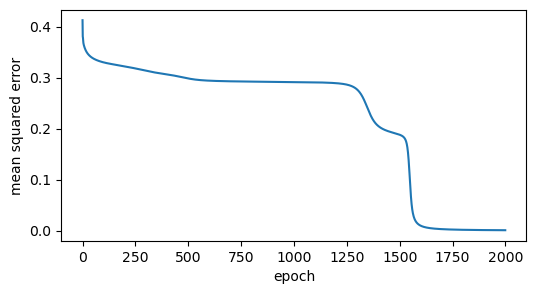

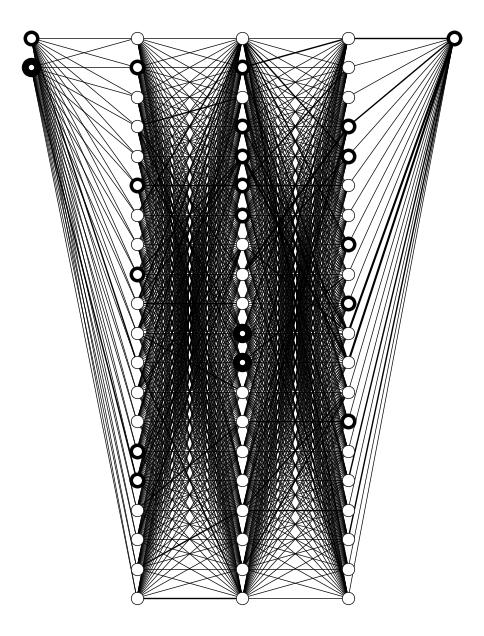

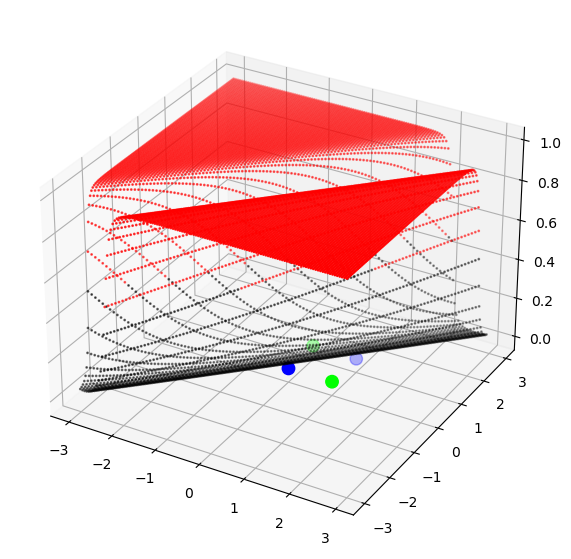

In [37]:
"""
Multilayer perceptron on XOR.
"""
import numpy as np
try:                                            # in Jupyter, override a backend set earlier in the session
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import matplotlib.pyplot as plt


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class Network:
    def __init__(self, sizes, eta, epochs):
        self.sizes, self.eta, self.epochs = sizes, eta, epochs
        n_in = [sizes[0]] + sizes[:-1]          # layer 0 has sizes[0] weights per neuron, as in the original
        self.w = [np.random.randn(n, m) for n, m in zip(sizes, n_in)]   # weights, random noise
        self.b = [np.random.randn(n) for n in sizes]                    # biases, random noise

    def feed_forward(self, x):
        self.out = []
        for w, b in zip(self.w, self.b):
            x = sigmoid(w @ x + b)              # activation: sigmoid of weighted inputs plus bias
            self.out.append(x)
        return x

    def back_propagate(self, y):
        self.delta = [None] * len(self.sizes)
        error = y - self.out[-1]                # error of the last layer
        for i in reversed(range(len(self.sizes))):
            s = self.out[i] * (1 - self.out[i]) # derivative of the sigmoid
            self.delta[i] = error * s
            error = self.w[i].T @ self.delta[i] # weighted deltas go to the layer below

    def update_weights(self, x):
        for i in range(len(self.sizes)):
            inp = x if i == 0 else self.out[i - 1]
            self.w[i] += self.eta * np.outer(self.delta[i], inp)
            self.b[i] += self.eta * self.delta[i]

    def train(self, data):
        np.random.shuffle(data)
        errors = []
        for e in range(self.epochs):
            sq_error = 0
            for x, y in data:
                out = self.feed_forward(x)
                sq_error += np.sum((y - out) ** 2)
                self.back_propagate(y)
                self.update_weights(x)
            errors.append(sq_error / len(data))
        return errors

    def display(self):                          # line width ~ weights, node edge width ~ biases
        fig, ax = plt.subplots(figsize=(6, 8))
        for i, size in enumerate(self.sizes):
            for j in range(size):
                if i > 0:
                    for k in range(self.sizes[i - 1]):
                        ax.plot([i - 1, i], [k, j], "k", lw=max(int(abs(self.w[i][j, k])), 1) / 2)
                ax.scatter(i, j, s=80, c="white", edgecolors="k", linewidths=max(5 * int(abs(self.b[i][j])), 1) / 2, zorder=3)
        ax.invert_yaxis()
        ax.axis("off")

    def graph(self, bound, increment):          # network output over a grid of the two inputs
        p = []
        for x in np.arange(-bound, bound, increment):
            for y in np.arange(-bound, bound, increment):
                p.append([x, y, self.feed_forward(np.array([x, y]))[0]])
        return np.array(p)


# the XOR training data: (input, output)
data = [(np.array([0, 0]), np.array([0])), (np.array([1, 1]), np.array([0])),
        (np.array([1, 0]), np.array([1])), (np.array([0, 1]), np.array([1]))]

sizes = [2, 20, 20, 20, 1]   # layer 0 has the dimension of the input, the last layer that of the output
eta = 0.5                    # learning rate
epochs = 2000                # passes over the training data

n = Network(sizes, eta, epochs)
errors = n.train(data)

plt.figure(figsize=(6, 3))
plt.plot(errors)
plt.xlabel("epoch")
plt.ylabel("mean squared error")
plt.show()

n.display()
plt.show()

p = n.graph(3, 0.05)
ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1, c=np.where(p[:, 2] > 0.5, "red", "black"))
ax.scatter([0, 1], [0, 1], [0, 0], s=80, c="blue")      # XOR points with output 0
ax.scatter([1, 0], [0, 1], [0, 0], s=80, c="lime")      # XOR points with output 1
plt.show()

seed 245, final loss 0.0004, 46 lines


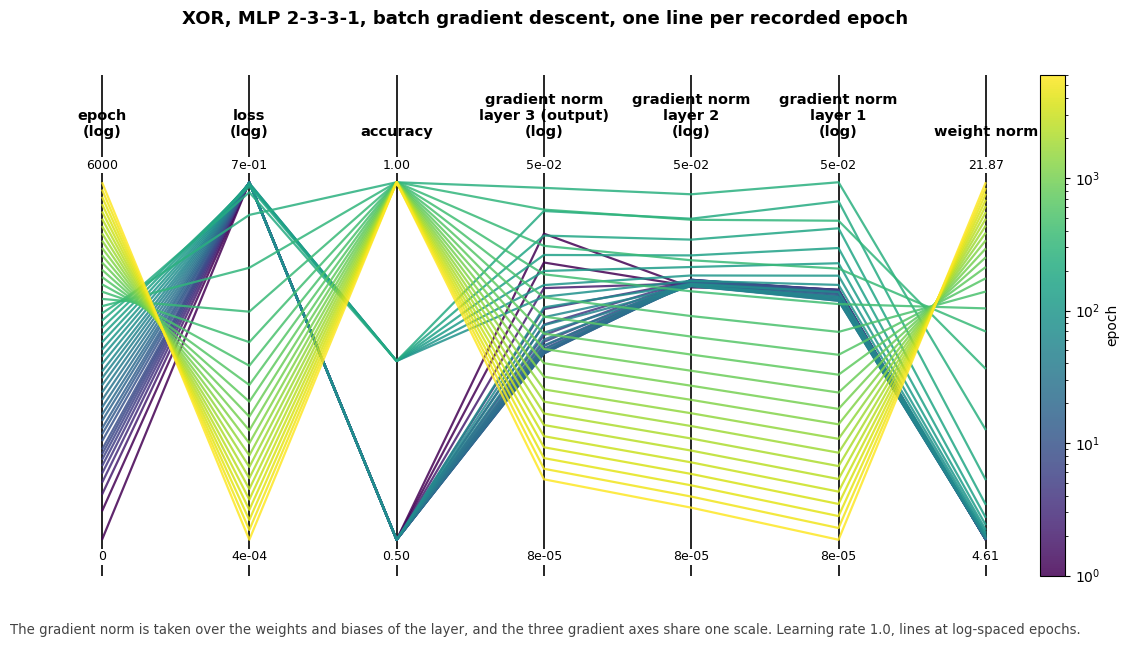

saved xor_parallel_coordinates.html


<IPython.core.display.Javascript object>

saved xor_parallel_coordinates


In [38]:
"""
Parallel coordinates of the training of the XOR network 2-3-3-1.

Source: 
Parikh, Deval. “Visualizing Backpropagation in Neural Network Training.” TDS Archive, 
January 14, 2022. 
https://medium.com/data-science/visualizing-backpropagation-in-neural-network-training-2647f5977fdb.

Every epoch is one line through a set of vertical axes (epoch, loss, metric) drawn with HiPlot.
Here the axes are extended by what backpropagation produces, the gradient norm of each layer,
so that the vanishing gradient and the point where training leaves the plateau become visible.

Network: 2-3-3-1, sigmoid everywhere, cross entropy, batch gradient descent with the formulas
dZ[L] = A[L] - Y, dZ[k-1] = (W[k]^T dZ[k]) * a(1-a), dW[k] = dZ[k] A[k-1]^T / n.

Output: xor_parallel_coordinates.png/.pdf, and xor_parallel_coordinates.html when hiplot
is installed (pip install hiplot), which gives the interactive version.
"""
import numpy as np
import matplotlib
try:                                            # in Jupyter the inline backend must stay active
    get_ipython()
except NameError:
    matplotlib.use("Agg")                       # plain script without a display
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

OUT = "xor_parallel_coordinates"
SIZES = [2, 3, 3, 1]
ALPHA, EPOCHS, SEED = 1.0, 6000, 245
REC = set(np.unique(np.round(np.logspace(0, np.log10(EPOCHS), 50)).astype(int))) | {0}   # log-spaced epochs

X = np.array([[0, 0, 1, 1], [0, 1, 0, 1]], dtype=float)      # examples as columns, m x n
Y = np.array([[0, 1, 1, 0]], dtype=float)
n = X.shape[1]


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def init(seed):
    rng = np.random.default_rng(seed)
    W = [rng.normal(0, 1, (SIZES[k + 1], SIZES[k])) for k in range(3)]
    b = [np.zeros((SIZES[k + 1], 1)) for k in range(3)]
    return W, b


def forward(W, b):
    A = [X]
    for Wk, bk in zip(W, b):
        A.append(sigmoid(Wk @ A[-1] + bk))
    return A


def backward(W, A):
    dZ = A[-1] - Y                                            # cross entropy with sigmoid
    gW, gb = [None] * 3, [None] * 3
    for k in (2, 1, 0):
        gW[k] = dZ @ A[k].T / n
        gb[k] = dZ.sum(axis=1, keepdims=True) / n
        if k > 0:
            dZ = (W[k].T @ dZ) * A[k] * (1 - A[k])
    return gW, gb


def train(seed):
    W, b = init(seed)
    rows = []
    for e in range(EPOCHS + 1):
        A = forward(W, b)
        p = np.clip(A[-1], 1e-12, 1 - 1e-12)
        loss = float(-np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p)))
        gW, gb = backward(W, A)
        if e in REC:
            gn = [float(np.sqrt(np.sum(gW[k] ** 2) + np.sum(gb[k] ** 2))) for k in range(3)]
            rows.append(dict(epoch=e, loss=loss, accuracy=float(np.mean((A[-1] > 0.5) == Y)),
                             grad_layer1=gn[0], grad_layer2=gn[1], grad_layer3=gn[2],
                             weight_norm=float(np.sqrt(sum((w ** 2).sum() for w in W)))))
        for k in range(3):
            W[k] -= ALPHA * gW[k]
            b[k] -= ALPHA * gb[k]
    return rows


# a 2-3-3-1 network can get stuck, so take the first of several seeds that learns XOR
for seed in [SEED] + list(range(300)):
    rows = train(seed)
    if rows[-1]["accuracy"] == 1.0:
        break
else:
    raise SystemExit("no seed converged")
print(f"seed {seed}, final loss {rows[-1]['loss']:.4f}, {len(rows)} lines")

# ------------------------------------------------------------------ static parallel coordinates
axes = [("epoch", "epoch", True), ("loss", "loss", True), ("accuracy", "accuracy", False),
        ("grad_layer3", "gradient norm\nlayer 3 (output)", True),
        ("grad_layer2", "gradient norm\nlayer 2", True),
        ("grad_layer1", "gradient norm\nlayer 1", True),
        ("weight_norm", "weight norm", False)]
M = np.array([[r[k] for k, _, _ in axes] for r in rows])
Z = np.zeros_like(M)
LOGV = {j: np.log10(np.maximum(M[:, j], 1e-12) + (1 if axes[j][0] == "epoch" else 0))
        for j, (_, _, lg) in enumerate(axes) if lg}
GR = [j for j, a in enumerate(axes) if a[0].startswith("grad")]
glo, ghi = min(LOGV[j].min() for j in GR), max(LOGV[j].max() for j in GR)     # one scale for all layers
for j, (_, _, lg) in enumerate(axes):
    v = LOGV[j] if lg else M[:, j]
    lo, hi = (glo, ghi) if j in GR else (v.min(), v.max())
    Z[:, j] = (v - lo) / (hi - lo + 1e-12)

fig, ax = plt.subplots(figsize=(13, 6.5))
xs = np.arange(len(axes))
segs = [np.column_stack([xs, Z[i]]) for i in range(len(rows))]
lc = LineCollection(segs, array=np.maximum(M[:, 0], 1), cmap="viridis", norm=matplotlib.colors.LogNorm(1, EPOCHS), linewidths=1.6, alpha=0.85)
ax.add_collection(lc)
for x in xs:
    ax.axvline(x, color="black", lw=1.2, zorder=0)
for j, (key, label, lg) in enumerate(axes):
    lo, hi = (10 ** glo, 10 ** ghi) if j in GR else (M[:, j].min(), M[:, j].max())
    fmt = (lambda v: f"{v:.0f}") if key == "epoch" else (lambda v: f"{v:.0e}") if lg else (lambda v: f"{v:.2f}" if key != "epoch" else f"{v:.0f}")
    ax.text(j, 1.03, fmt(hi), ha="center", va="bottom", fontsize=9, bbox=dict(fc="white", ec="none", pad=1), zorder=6)
    ax.text(j, -0.03, fmt(lo), ha="center", va="top", fontsize=9, bbox=dict(fc="white", ec="none", pad=1), zorder=6)
    ax.text(j, 1.12, label + ("\n(log)" if lg else ""), ha="center", va="bottom", fontsize=10.5,
            fontweight="bold")
ax.set_xlim(-0.3, len(axes) - 0.7)
ax.set_ylim(-0.1, 1.3)
ax.axis("off")
cb = fig.colorbar(lc, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("epoch")
fig.suptitle("XOR, MLP 2-3-3-1, batch gradient descent, one line per recorded epoch", fontsize=13,
             fontweight="bold")
fig.text(0.5, 0.02, "The gradient norm is taken over the weights and biases of the layer, and the three gradient axes share one scale. "
         f"Learning rate {ALPHA}, lines at log-spaced epochs.", ha="center", fontsize=9.5, color="#444444")
fig.savefig(OUT + ".png", dpi=200, bbox_inches="tight")
fig.savefig(OUT + ".pdf", bbox_inches="tight")
plt.show()                                      # displays inline in Jupyter, does nothing under Agg

# ------------------------------------------------------------------ interactive version
try:
    import hiplot as hip
    exp = hip.Experiment.from_iterable(rows)
    exp.to_html(OUT + ".html")
    print("saved", OUT + ".html")
    try:
        get_ipython()
        exp.display()                           # interactive plot below the cell in Jupyter
    except NameError:
        pass
except ImportError:
    print("hiplot not installed, pip install hiplot gives the interactive html")
print("saved", OUT)